In [1]:
from google.colab import drive
drive.mount('/content/drive/')


Drive already mounted at /content/drive/; to attempt to forcibly remount, call drive.mount("/content/drive/", force_remount=True).


In [2]:
import pandas as pd
import os, json

file = "listings.csv.gz"
path = '/content/drive/MyDrive/Colab Notebooks/airbnb-santiago-sagemaker-pipeline'

df = pd.read_csv(path + '/' + file)

print(df.shape)

df.head(10)




(18904, 90)


,id,listing_url,scrape_id,last_scraped,source,name,description,neighborhood_overview,picture_url,host_id,...,review_scores_communication,review_scores_location,review_scores_value,license,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,49392,https://www.airbnb.com/rooms/49392,20260923225049,2026-09-26,NaN,Share my Flat in Providencia,<b>The space</b><br />Departamento en el barri...,NaN,https://a0.muscache.com/pictures/3740612/b1850...,224592,...,NaN,NaN,NaN,NaN,NaN,1,0,1,0,NaN
1,52811,https://www.airbnb.com/rooms/52811,20260923225049,2026-09-26,NaN,Suite Providencia 1 Santiago Chile,Apartment located on the subway station Manuel...,NaN,https://a0.muscache.com/pictures/miso/Hosting-...,244792,...,4.59,4.64,4.36,NaN,NaN,3,3,0,0,0.23
2,80482,https://www.airbnb.com/rooms/80482,20260923225049,2026-09-25,NaN,Room Private for Woman,"Near transport, subway, malls supermarkets, wa...",NaN,https://a0.muscache.com/pictures/3633153/dffd5...,154527,...,NaN,NaN,NaN,NaN,NaN,2,0,2,0,NaN
3,88944,https://www.airbnb.com/rooms/88944,20260923225049,2026-09-26,NaN,COZY APT. PROVIDENCIA METRO WIFI TV,Spacious and cozy apartment. It has excellent ...,NaN,https://a0.muscache.com/pictures/8fd1c60d-5a8f...,485358,...,4.89,4.96,4.73,NaN,NaN,1,1,0,0,1.37
4,90694,https://www.airbnb.com/rooms/90694,20260923225049,2026-09-26,NaN,Apartment x Rent in Providencia 802,APARTMENT<br />Furnished Apartments with one b...,NaN,https://a0.muscache.com/pictures/d29b8d52-ca46...,491253,...,4.83,4.77,4.43,NaN,NaN,2,2,0,0,0.41
5,90769,https://www.airbnb.com/rooms/90769,20260923225049,2026-09-26,NaN,New & Warm Apartment in Providencia,"This is a 1 Bedroom Apartment, 1 living room,...",NaN,https://a0.muscache.com/pictures/664437/2b5b40...,491253,...,5.00,4.85,4.69,NaN,NaN,2,2,0,0,0.07
6,123569,https://www.airbnb.com/rooms/123569,20260923225049,2026-09-26,NaN,Habitación Single,<b>The space</b><br />It is a south-facing roo...,NaN,https://a0.muscache.com/pictures/1055258/51640...,617378,...,NaN,NaN,NaN,NaN,NaN,1,0,1,0,NaN
7,136438,https://www.airbnb.com/rooms/136438,20260923225049,2026-09-26,NaN,Fully Furnished Apartment Providencia,<b>The space</b><br />Apartment : <br />Presti...,NaN,https://a0.muscache.com/pictures/3671201/6680f...,667910,...,4.86,4.94,4.86,NaN,NaN,20,20,0,0,1.58
8,154615,https://www.airbnb.com/rooms/154615,20260923225049,2026-09-26,NaN,Furnished apartment near Metro,<b>The space</b><br />Small apartment (25 m2) ...,NaN,https://a0.muscache.com/pictures/3632503/9bbc9...,743719,...,4.81,4.94,4.60,NaN,NaN,3,3,0,0,0.47
9,181005,https://www.airbnb.com/rooms/181005,20260923225049,2026-09-26,NaN,Private Room in Barrio Bellavista,One (1) room private and bathroom in Neighbor...,NaN,https://a0.muscache.com/pictures/airflow/Hosti...,867345,...,4.50,4.25,4.25,NaN,NaN,1,0,1,0,0.06


In [3]:
print(df.dtypes.value_counts())

float64    37
object     29
int64      24
Name: count, dtype: int64


Revisión de campos nulos.

In [4]:
df.isnull().mean().sort_values(ascending=False).head(20)

,0
neighborhood_overview,1.000000
host_since,1.000000
host_response_time,1.000000
host_thumbnail_url,1.000000
host_acceptance_rate,1.000000
host_response_rate,1.000000
host_verifications,1.000000
neighbourhood,1.000000
host_total_listings_count,1.000000
host_neighbourhood,1.000000


Borrar filas vacías con más de un 90% de nulos.

In [5]:
nulos = df.isnull().mean()
columnas_vacias = nulos[nulos > 0.9].index.tolist()
print(len(columnas_vacias),columnas_vacias)

df = df.drop(columns=columnas_vacias)
print(df.shape)


16 ['source', 'neighborhood_overview', 'host_since', 'host_response_time', 'host_response_rate', 'host_acceptance_rate', 'host_thumbnail_url', 'host_neighbourhood', 'host_total_listings_count', 'host_verifications', 'neighbourhood', 'neighbourhood_group_cleansed', 'bathrooms', 'calendar_updated', 'license', 'instant_bookable']
(18904, 74)


Selección de columnas útiles para predecir el precio.

In [6]:
columnas = [
    "room_type", "property_type", "accommodates", "bedrooms", "beds",
    "bathrooms_text", "neighbourhood_cleansed", "latitude", "longitude",
    "host_is_superhost", "host_listings_count", "host_identity_verified",
    "number_of_reviews", "review_scores_rating", "review_scores_location",
    "reviews_per_month", "minimum_nights", "availability_365", "price"
]
df_modelo = df[columnas].copy()
print(df_modelo.shape)
df_modelo.head()

(18904, 19)


,room_type,property_type,accommodates,bedrooms,beds,bathrooms_text,neighbourhood_cleansed,latitude,longitude,host_is_superhost,host_listings_count,host_identity_verified,number_of_reviews,review_scores_rating,review_scores_location,reviews_per_month,minimum_nights,availability_365,price
0,Private room,Private room in rental unit,1,1.0,1.0,NaN,Providencia,-33.43277,-70.59892,f,2,t,0,NaN,NaN,NaN,3.0,268,"$59,303.00"
1,Entire home/apt,Entire rental unit,4,1.0,1.0,1 bath,Providencia,-33.42959,-70.61880,f,3,t,45,4.42,4.64,0.23,1.0,271,"$94,244.00"
2,Private room,Private room in home,2,1.0,1.0,1 shared bath,La Florida,-33.51922,-70.59152,f,2,t,0,NaN,NaN,NaN,2.0,363,NaN
3,Entire home/apt,Entire condo,2,1.0,1.0,1 bath,Providencia,-33.42141,-70.60832,t,1,t,249,4.74,4.96,1.37,2.0,328,"$79,337.50"
4,Entire home/apt,Entire rental unit,2,1.0,1.0,1 bath,Providencia,-33.42629,-70.61866,t,2,t,76,4.65,4.77,0.41,4.0,364,"$81,250.00"


Limpieza de price

In [7]:
df_modelo["price"]= (df_modelo["price"]).str.replace(r"[$,]","", regex=True).astype(float)

pd.set_option("display.float_format", "{:,.0f}".format)

print(df_modelo["price"].describe())
print("Nulos:", df_modelo["price"].isnull().sum())





count       18,006
mean       108,446
std      1,175,339
min          8,463
25%         40,000
50%         55,106
75%         81,560
max     97,573,964
Name: price, dtype: float64
Nulos: 898


Representación gráfica de los precios

In [8]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

def graficar_distribucion(serie, titulo, unidad="", bins=60, guardar=None):
    """
    Grafica histograma, boxplot e histograma del logaritmo de una columna numérica.

    serie:   columna a graficar, por ejemplo df["price"]
    titulo:  texto para los títulos de los gráficos
    unidad:  etiqueta del eje x, por ejemplo "CLP por noche"
    bins:    número de barras del histograma
    guardar: ruta del archivo para guardar la imagen (opcional)
    """
    serie = serie.dropna()
    mediana = serie.median()

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    # Histograma
    sns.histplot(serie, bins=bins, ax=axes[0])
    axes[0].axvline(mediana, color="red", linestyle="--", label=f"Mediana: {mediana:,.0f}")
    axes[0].set_title(f"{titulo}: histograma")
    axes[0].set_xlabel(unidad)
    axes[0].legend()

    # Boxplot
    sns.boxplot(x=serie, ax=axes[1])
    axes[1].set_title(f"{titulo}: boxplot")
    axes[1].set_xlabel(unidad)

    # Histograma del logaritmo
    sns.histplot(np.log1p(serie), bins=bins, ax=axes[2])
    axes[2].set_title(f"{titulo}: log")
    axes[2].set_xlabel(f"log({unidad})" if unidad else "log")

    plt.tight_layout()
    if guardar:
        plt.savefig(guardar, dpi=150, bbox_inches="tight")
        print(f"Imagen guardada en: {guardar}")
    plt.show()

Imagen guardada en: /content/drive/MyDrive/Colab Notebooks/airbnb-santiago-sagemaker-pipeline/images/01_distribucion_precios_crudos.png


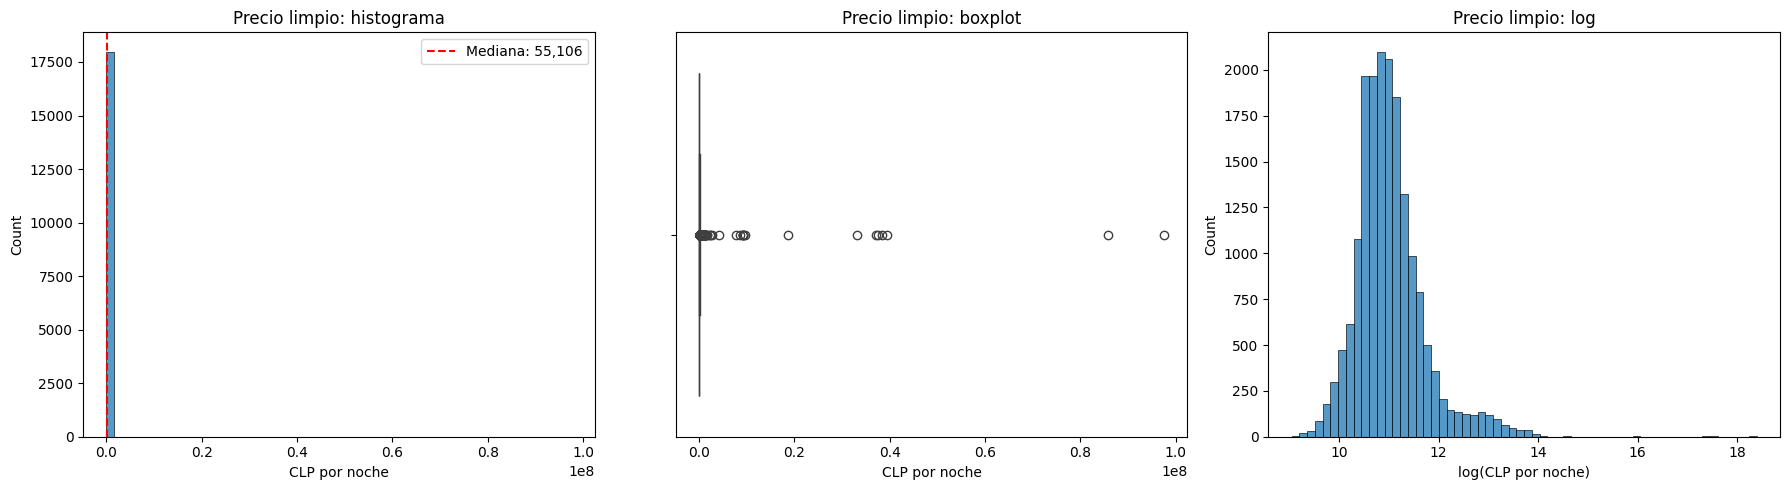

In [9]:
# Ver el gráfico
#graficar_distribucion(df_modelo["price"], "Precio", "CLP por noche")

# Verlo y guardarlo en Drive como evidencia
os.makedirs(path + "/images", exist_ok=True)

graficar_distribucion(
    df_modelo["price"], "Precio crudo", "CLP por noche",
    guardar=path + "/images/01_distribucion_precios_crudos.png"
)

# Sirve para cualquier otra columna numérica
#graficar_distribucion(df_modelo["accommodates"], "Capacidad", "personas", bins=16)

Aplicar el corte del percentil 99

In [10]:
# Eliminar filas sin precio
df_modelo = df_modelo.dropna(subset=["price"])

# Eliminar outliers sobre el percentil 99
corte = df_modelo["price"].quantile(0.99)
df_modelo = df_modelo[df_modelo["price"] <= corte]

print(f"Corte P99: {corte:,.0f} CLP")
print(df_modelo.shape)
print(df_modelo["price"].describe())

Corte P99: 629,811 CLP
(17825, 19)
count    17,825
mean     75,756
std      75,031
min       8,463
25%      39,849
50%      55,000
75%      80,240
max     629,078
Name: price, dtype: float64


Imagen guardada en: /content/drive/MyDrive/Colab Notebooks/airbnb-santiago-sagemaker-pipeline/images/02_distribucion_precios_limpios.png


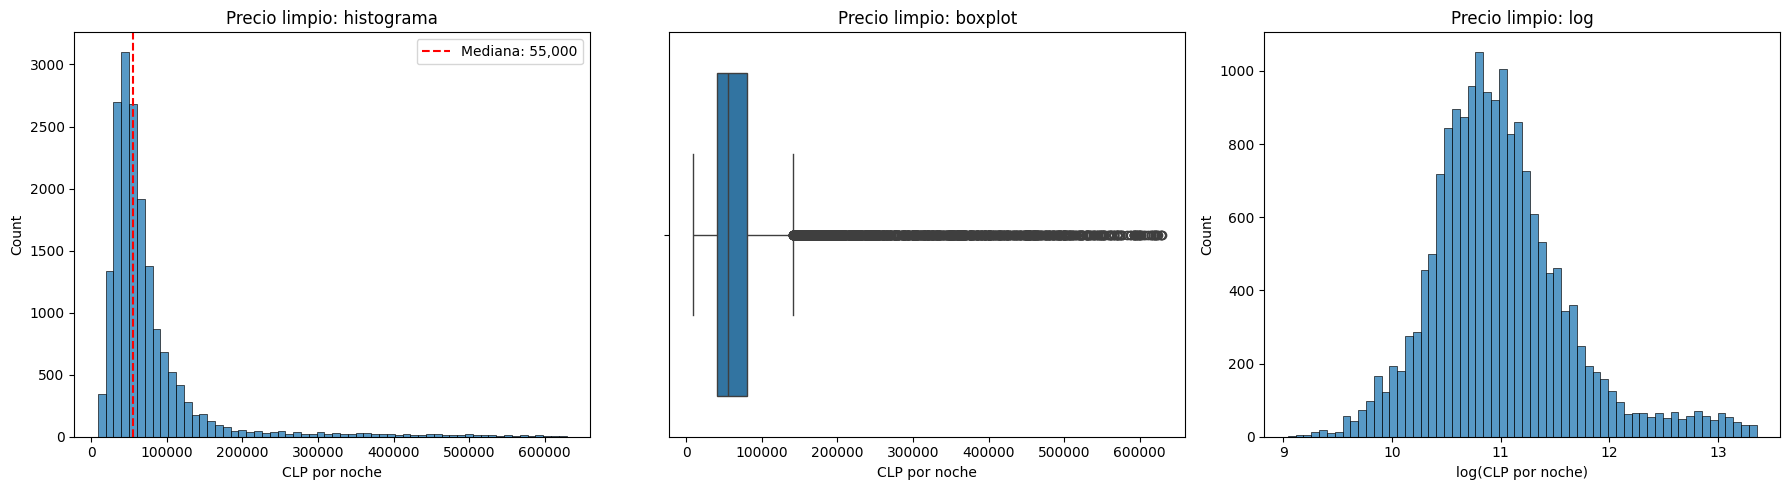

In [11]:
graficar_distribucion(
    df_modelo["price"], "Precio limpio", "CLP por noche",
    guardar=path + "/images/02_distribucion_precios_limpios.png"
)

Conversión de columnas

In [12]:
import numpy as np

def convertir_banos(df):
    txt = df["bathrooms_text"].fillna("").str.lower()
    num = txt.str.extract(r"(\d+\.?\d*)")[0].astype(float)
    num = num.where(~txt.str.contains("half"), 0.5)
    df["banos"] = num.fillna(num.median())
    df["bano_compartido"] = txt.str.contains("shared").astype(int)
    return df.drop(columns=["bathrooms_text"])

def convertir_binarias(df, columnas):
    for c in columnas:
        df[c] = (df[c] == "t").astype(int)
    return df

def tratar_resenas(df):
    df["sin_resenas"] = df["review_scores_rating"].isnull().astype(int)
    df["reviews_per_month"] = df["reviews_per_month"].fillna(0)
    for c in ["review_scores_rating", "review_scores_location"]:
        df[c] = df[c].fillna(df[c].median())
    return df

def rellenar_mediana(df, columnas):
    for c in columnas:
        df[c] = df[c].fillna(df[c].median())
    return df

def agrupar_categorias(df, columna, top=10):
    principales = df[columna].value_counts().nlargest(top).index
    df[columna] = df[columna].where(df[columna].isin(principales), "Otro")
    return df

# Aplicar todo
df_modelo = convertir_banos(df_modelo)
df_modelo = convertir_binarias(df_modelo, ["host_is_superhost", "host_identity_verified"])
df_modelo = tratar_resenas(df_modelo)
df_modelo = rellenar_mediana(df_modelo, ["bedrooms", "beds", "minimum_nights"])

print(df_modelo.shape)
print("Nulos restantes:", df_modelo.isnull().sum().sum())
df_modelo.head()

(17825, 21)
Nulos restantes: 0


,room_type,property_type,accommodates,bedrooms,beds,neighbourhood_cleansed,latitude,longitude,host_is_superhost,host_listings_count,...,number_of_reviews,review_scores_rating,review_scores_location,reviews_per_month,minimum_nights,availability_365,price,banos,bano_compartido,sin_resenas
0,Private room,Private room in rental unit,1,1,1,Providencia,-33,-71,0,2,...,0,5,5,0,3,268,"59,303",1,0,1
1,Entire home/apt,Entire rental unit,4,1,1,Providencia,-33,-71,0,3,...,45,4,5,0,1,271,"94,244",1,0,0
3,Entire home/apt,Entire condo,2,1,1,Providencia,-33,-71,1,1,...,249,5,5,1,2,328,"79,338",1,0,0
4,Entire home/apt,Entire rental unit,2,1,1,Providencia,-33,-71,1,2,...,76,5,5,0,4,364,"81,250",1,0,0
5,Entire home/apt,Entire condo,2,1,1,Providencia,-33,-71,1,2,...,14,5,5,0,4,347,"81,250",1,0,0


Correlación de variables

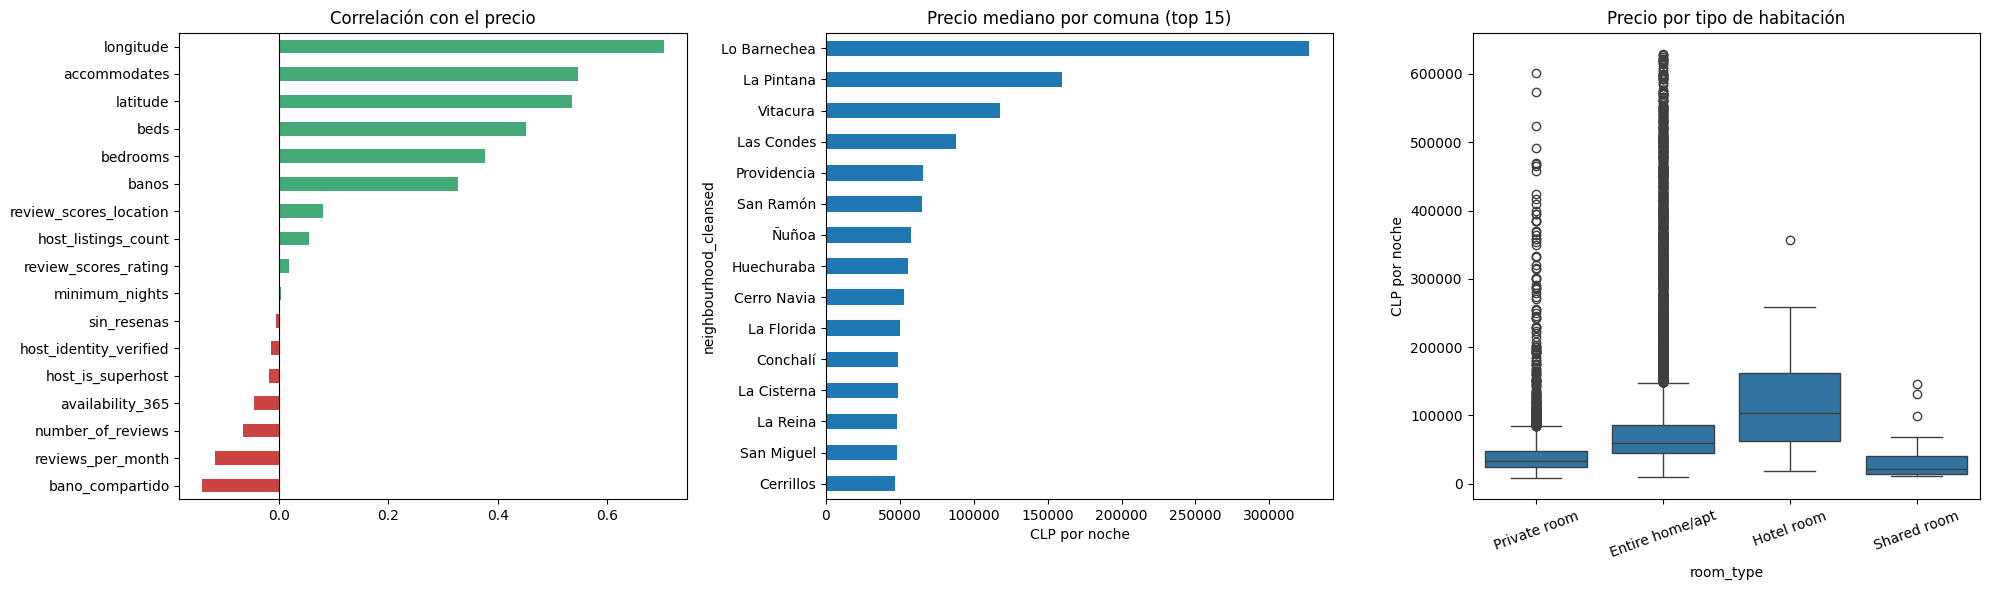

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# 1. Correlación de las variables numéricas con el precio
corr = (df_modelo.select_dtypes("number")
        .corr()["price"]
        .drop("price")
        .sort_values())
corr.plot.barh(ax=axes[0], color=["#c44" if v < 0 else "#4a7" for v in corr])
axes[0].set_title("Correlación con el precio")
axes[0].axvline(0, color="black", linewidth=0.8)

# 2. Precio mediano por comuna (las 15 más caras)
comunas = (df_modelo.groupby("neighbourhood_cleansed")["price"]
           .median().sort_values().tail(15))
comunas.plot.barh(ax=axes[1])
axes[1].set_title("Precio mediano por comuna (top 15)")
axes[1].set_xlabel("CLP por noche")

# 3. Precio por tipo de habitación
sns.boxplot(data=df_modelo, x="room_type", y="price", ax=axes[2])
axes[2].set_title("Precio por tipo de habitación")
axes[2].set_ylabel("CLP por noche")
axes[2].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.savefig(path + "/images/03_relacion_con_precio.png",
            dpi=150, bbox_inches="tight")
plt.show()

Se realiza un gráfico espacial dado que llama la atencion que la longitud y la latitud estén tan fuertemente relacionadas con el precio.

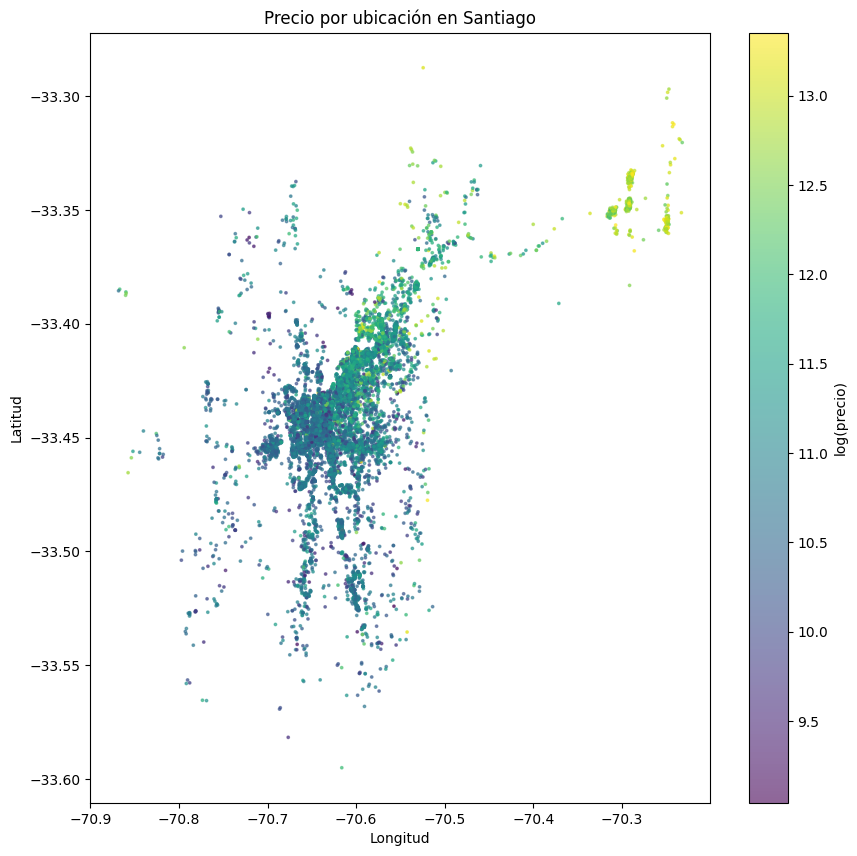

neighbourhood_cleansed
Cerrillos              18
Lo Prado               15
Conchalí               12
La Granja               9
Pedro Aguirre Cerda     7
El Bosque               7
Cerro Navia             4
Lo Espejo               3
La Pintana              1
San Ramón               1
Name: count, dtype: int64


In [14]:
fig, ax = plt.subplots(figsize=(10, 10))
sc = ax.scatter(df_modelo["longitude"], df_modelo["latitude"],
                c=np.log1p(df_modelo["price"]), cmap="viridis", s=3, alpha=0.6)
plt.colorbar(sc, label="log(precio)")
ax.set_title("Precio por ubicación en Santiago")
ax.set_xlabel("Longitud")
ax.set_ylabel("Latitud")
plt.savefig(path + "/images/04_mapa_precios.png",
            dpi=150, bbox_inches="tight")
plt.show()

print(df_modelo["neighbourhood_cleansed"].value_counts().tail(10))

In [15]:
import plotly.express as px
import numpy as np

def mapa_precios(df, titulo, estilo="carto-positron", zoom=10, height=750):
    """
    Dibuja un mapa interactivo de los anuncios coloreados por log(precio).

    df:     DataFrame con latitude, longitude, price, neighbourhood_cleansed y room_type
    titulo: título del mapa
    estilo: mapa base ("carto-positron", "carto-darkmatter", "carto-voyager")
    zoom:   nivel de zoom inicial
    height: alto del mapa en píxeles
    """
    df_mapa = df.copy()
    df_mapa["log_precio"] = np.log1p(df_mapa["price"])

    fig = px.scatter_map(
        df_mapa,
        lat="latitude", lon="longitude",
        color="log_precio",
        color_continuous_scale="Plasma",
        hover_data={"price": ":,.0f", "neighbourhood_cleansed": True,
                    "room_type": True, "log_precio": False},
        zoom=zoom, height=height,
        map_style=estilo,
        opacity=0.6,
    )
    fig.update_traces(marker=dict(size=4))
    fig.update_layout(title=f"{titulo} ({len(df):,} anuncios)")
    fig.show()

In [16]:
mapa_precios(df_modelo, "Precio por ubicación — Santiago urbano + cordillera, sep 2026")

Se excluye los centros de sky cuyos precios por noche son elevados y distorsionarán los precios de la ciudad

In [17]:
LONGITUD_CORTE = -70.48

df_antes_corte = df_modelo.copy()   # copia ANTES del corte, para comparar

antes = len(df_modelo)
df_modelo = df_modelo[df_modelo["longitude"] <= LONGITUD_CORTE]

print(f"Eliminados: {antes - len(df_modelo)} anuncios de centros de ski")
print(df_modelo.shape)

Eliminados: 569 anuncios de centros de ski
(17256, 21)


In [18]:
mapa_precios(df_modelo, "Precio por ubicación — Santiago urbano, sep 2026")

Al remover los alojamientos mayormente turísticos y de alto valor de la cordillera es necesario relacionar nuevamente las variables en relación al precio.

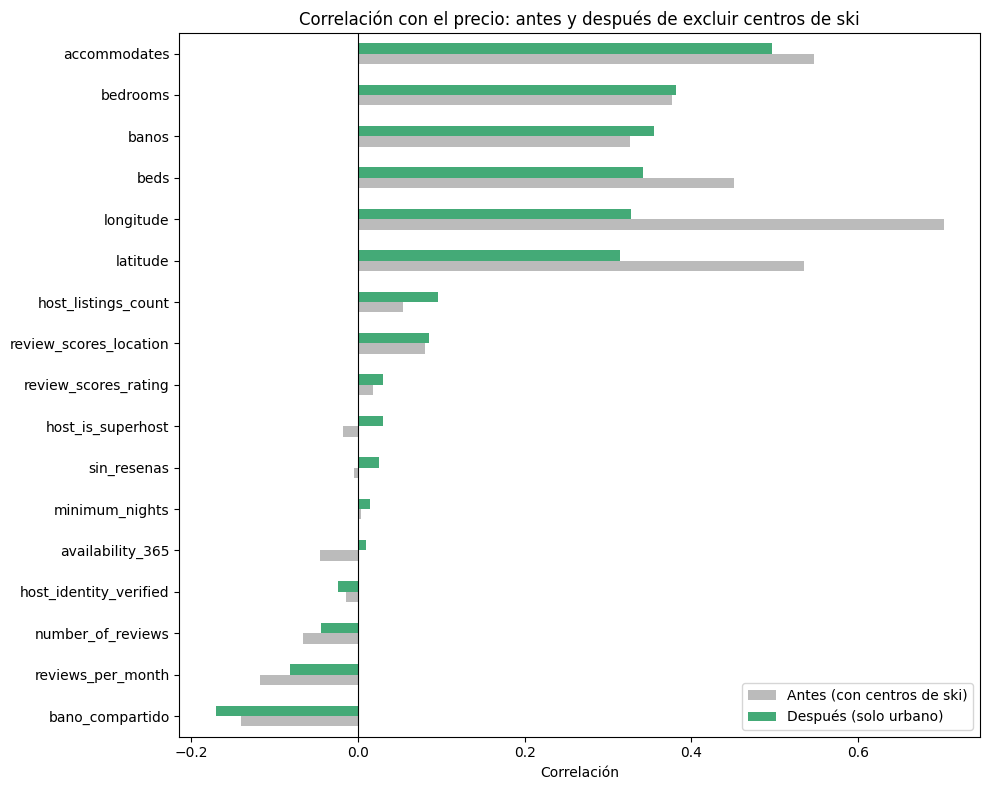

                        Antes (con centros de ski)  Después (solo urbano)
bano_compartido                                 -0                     -0
reviews_per_month                               -0                     -0
number_of_reviews                               -0                     -0
host_identity_verified                          -0                     -0
availability_365                                -0                      0
minimum_nights                                   0                      0
sin_resenas                                     -0                      0
host_is_superhost                               -0                      0
review_scores_rating                             0                      0
review_scores_location                           0                      0
host_listings_count                              0                      0
latitude                                         1                      0
longitude                             

In [19]:
def correlacion_con_precio(df):
    return (df.select_dtypes("number")
            .corr()["price"]
            .drop("price"))

corr_antes = correlacion_con_precio(df_antes_corte)
corr_despues = correlacion_con_precio(df_modelo)

comparacion = pd.DataFrame({
    "Antes (con centros de ski)": corr_antes,
    "Después (solo urbano)": corr_despues
}).dropna().sort_values("Después (solo urbano)")

fig, ax = plt.subplots(figsize=(10, 8))
comparacion.plot.barh(ax=ax, color=["#bbb", "#4a7"])
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Correlación con el precio: antes y después de excluir centros de ski")
ax.set_xlabel("Correlación")

plt.tight_layout()
plt.savefig(path + "/images/07_correlacion_antes_despues.png",
            dpi=150, bbox_inches="tight")
plt.show()

print(comparacion.round(2))

Filtro de precios sospechosos y variables premium

In [20]:
import json
import numpy as np

# --- 1. Eliminar precios sospechosos (solo para entrenar) ---
TOPE_HABITACION = 150_000
TOPE_POR_HUESPED = 150_000

es_habitacion = df_modelo["room_type"].isin(["Private room", "Shared room"])
es_completa = df_modelo["room_type"] == "Entire home/apt"
precio_por_huesped = df_modelo["price"] / df_modelo["accommodates"].clip(lower=1)

sospechoso = (es_habitacion & (df_modelo["price"] > TOPE_HABITACION)) | \
             (es_completa & (precio_por_huesped > TOPE_POR_HUESPED))

print(f"Precios sospechosos eliminados: {sospechoso.sum()} "
      f"(habitaciones: {(es_habitacion & sospechoso).sum()}, completas: {(es_completa & sospechoso).sum()})")
df_modelo = df_modelo[~sospechoso].copy()

# --- 2. Variables premium ---
extra = df.loc[df_modelo.index, ["amenities", "name", "calculated_host_listings_count_entire_homes"]]

amenities = extra["amenities"].fillna("[]").apply(lambda s: [a.lower() for a in json.loads(s)])
df_modelo["n_amenities"] = amenities.apply(len)

amenities_clave = {
    "tiene_estacionamiento": "free parking",
    "tiene_aire":            "air conditioning",
    "tiene_piscina":         "pool",
    "tiene_jacuzzi":         "hot tub",
    "tiene_gimnasio":        "gym",
    "tiene_lavavajillas":    "dishwasher",
    "tiene_calefaccion":     "heating",
}
for col, texto in amenities_clave.items():
    df_modelo[col] = amenities.apply(lambda lista: int(any(texto in a for a in lista)))

EL_GOLF = (-33.4150, -70.5983)
def distancia_km(lat, lon, punto):
    lat1, lon1, lat2, lon2 = map(np.radians, [lat, lon, punto[0], punto[1]])
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 2 * 6371 * np.arcsin(np.sqrt(a))
df_modelo["dist_el_golf_km"] = distancia_km(df_modelo["latitude"], df_modelo["longitude"], EL_GOLF)

df_modelo["titulo_premium"] = (extra["name"].fillna("").str.lower()
                               .str.contains("lujo|luxury|premium|exclusiv").astype(int))
df_modelo["calculated_host_listings_count_entire_homes"] = extra["calculated_host_listings_count_entire_homes"]

print(df_modelo.shape)
print("Nulos restantes:", df_modelo.isnull().sum().sum())

Precios sospechosos eliminados: 78 (habitaciones: 62, completas: 16)
(17178, 32)
Nulos restantes: 0


Selección y agrupación de variables antes de pasarlas por OneHotEncoder

In [21]:
import pandas as pd

def agrupar_raras(serie, minimo, etiqueta):
    conteo = serie.value_counts()
    validas = conteo[conteo >= minimo].index
    return serie.where(serie.isin(validas), etiqueta)

df_modelo['property_type'] = agrupar_raras(df_modelo['property_type'], 50, 'Otro')
df_modelo['neighbourhood_cleansed'] = agrupar_raras(df_modelo['neighbourhood_cleansed'], 30, 'Otra comuna')

# Revisión rápida: deberían quedar 16 y 22 categorías
print(df_modelo['property_type'].nunique(), df_modelo['neighbourhood_cleansed'].nunique())

cat_cols = ['room_type', 'property_type', 'neighbourhood_cleansed']
df_modelo_ohe = pd.get_dummies(df_modelo, columns=cat_cols, dtype=int)

# Guarda las columnas finales para usar las mismas en la inferencia
columnas_modelo = df_modelo_ohe.columns.tolist()
print(df_modelo_ohe.shape)

16 22
(17178, 71)


## Registro y guardado de versiones
Se define antes del primer entrenamiento para guardar cada modelo en Drive en el momento en que se entrena (sin volver a entrenarlo). Cada versión queda en `/modelos/<version>/` con el modelo, sus hiperparámetros, las métricas y la lista de columnas que necesita para predecir.

In [ ]:
import os, json
from datetime import datetime
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# --- Tabla de versiones ---
# v1 no se guardó como modelo: queda registrada solo con sus métricas
versiones = [
    {'version': 'v1', 'descripcion': 'Base, sin filtro', 'MAE': 14533, 'RMSE': 30201, 'R2': 0.595},
]

def registrar_version(version, descripcion, pred):
    """Agrega (o reemplaza, si se vuelve a correr) una versión en la tabla."""
    fila = {
        'version': version, 'descripcion': descripcion,
        'MAE': round(mean_absolute_error(real, pred)),
        'RMSE': round(mean_squared_error(real, pred) ** 0.5),
        'R2': round(r2_score(real, pred), 3),
    }
    versiones[:] = [v for v in versiones if v['version'] != version] + [fila]

# --- Guardar cada versión en Drive: /modelos/<version>/ ---
# Usa X_train, X_test y real del momento en que se llama (después de entrenar)
def guardar_version(version, modelo, params, accion, pred):
    carpeta = os.path.join(path + "/modelos", version)
    os.makedirs(carpeta, exist_ok=True)

    modelo.save_model(os.path.join(carpeta, 'modelo.json'))
    json.dump(params, open(os.path.join(carpeta, 'hiperparametros.json'), 'w'), indent=2)
    json.dump(list(X_train.columns), open(os.path.join(carpeta, 'columnas.json'), 'w'), indent=2)

    metricas = {
        'version': version, 'accion': accion,
        'fecha': datetime.now().strftime('%Y-%m-%d %H:%M'),
        'filas_train': len(X_train), 'filas_test': len(X_test), 'n_columnas': X_train.shape[1],
        'MAE': round(mean_absolute_error(real, pred)),
        'RMSE': round(mean_squared_error(real, pred) ** 0.5),
        'R2': round(r2_score(real, pred), 3),
    }
    json.dump(metricas, open(os.path.join(carpeta, 'metricas.json'), 'w'), indent=2)

    pd.DataFrame(versiones).to_csv(os.path.join(path + "/modelos", 'versiones.csv'), index=False)
    print(f"✓ {version} guardada en {carpeta}")


In [22]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor

X = df_modelo_ohe.drop(columns=['price'])
y = np.log1p(df_modelo_ohe['price'])          # entrenamos sobre log(precio)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

params_v2 = dict(n_estimators=500, learning_rate=0.05, max_depth=6, min_child_weight=1,
                 subsample=0.8, colsample_bytree=0.8, reg_lambda=1)
modelo = XGBRegressor(**params_v2, random_state=42)
modelo.fit(X_train, y_train, eval_set=[(X_test, y_test)], verbose=False)

pred = np.expm1(modelo.predict(X_test))   # de vuelta a CLP
real = np.expm1(y_test)

print(f"MAE : {mean_absolute_error(real, pred):,.0f} CLP")
print(f"RMSE: {mean_squared_error(real, pred) ** 0.5:,.0f} CLP")
print(f"R²  : {r2_score(real, pred):.3f}")

# Referencia ingenua: predecir siempre la mediana
print(f"MAE mediana: {mean_absolute_error(real, np.full_like(real, real.median())):,.0f} CLP")

# Registrar y guardar v2 en el momento en que se entrena
registrar_version('v2', 'Filtro sospechosos + premium', pred)
guardar_version('v2', modelo, params_v2, 'Filtro sospechosos + premium', pred)

import pandas as pd
pd.Series(modelo.feature_importances_, index=X.columns).nlargest(15)

MAE : 13,109 CLP
RMSE: 25,915 CLP
R²  : 0.673
MAE mediana: 27,215 CLP


,0
room_type_Private room,0
room_type_Entire home/apt,0
bedrooms,0
accommodates,0
property_type_Room in hotel,0
neighbourhood_cleansed_Las Condes,0
tiene_estacionamiento,0
bano_compartido,0
banos,0
longitude,0


In [23]:
res = pd.DataFrame({'real': real.values, 'pred': pred}, index=X_test.index)
res['err'] = (res.pred - res.real).abs()
res['tramo'] = pd.qcut(res.real, 5, labels=['muy bajo','bajo','medio','alto','muy alto'])
print(res.groupby('tramo')['err'].agg(['mean','median','count']).round(0))
print(res.sort_values('err', ascending=False).head(10).join(df_modelo[['property_type','neighbourhood_cleansed','room_type']]))

           mean  median  count
tramo                         
muy bajo  7,345   5,836    692
bajo      6,587   4,795    683
medio     7,806   5,892    687
alto     10,892   8,556    687
muy alto 32,919  19,073    687
         real    pred     err     tramo              property_type  \
462   478,272  80,653 397,619  muy alto         Entire rental unit   
5816  500,000 185,284 314,716  muy alto         Entire rental unit   
13994 376,521  75,546 300,975  muy alto         Entire rental unit   
10716 494,689 216,832 277,858  muy alto               Entire condo   
3959  394,928 172,690 222,238  muy alto                       Otro   
15512 348,669 129,046 219,623  muy alto                Entire home   
5019  361,598 142,315 219,283  muy alto                Entire home   
8768  261,479  48,309 213,170  muy alto  Entire serviced apartment   
1691  250,000  53,824 196,176  muy alto         Entire rental unit   
1980  238,000  45,453 192,547  muy alto         Entire rental unit   

      neighb

/tmp/ipykernel_59511/1819013855.py:4: FutureWarning:

The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.



## v3 · Ajuste de hiperparámetros y registro de experimentos
Se ajusta un hiperparámetro a la vez con validación cruzada (5 folds) sobre el train. Cada prueba queda en una tabla y cada versión del modelo (v1, v2, v3…) en una tabla comparativa.

In [24]:
import pandas as pd
from sklearn.model_selection import cross_val_score

pd.reset_option("display.float_format")   # mostrar decimales en las tablas (MAE_cv_log, R2)

pruebas_log = []   # aquí queda cada prueba de hiperparámetros

# --- Ajuste incremental ---
base = dict(n_estimators=500, learning_rate=0.05, max_depth=6,
            subsample=0.8, colsample_bytree=0.8, random_state=42, n_jobs=-1)

def probar(param, valores):
    for v in valores:
        cfg = {**base, param: v}
        mae = -cross_val_score(XGBRegressor(**cfg), X_train, y_train, cv=5,
                               scoring='neg_mean_absolute_error').mean()
        pruebas_log.append({'parametro': param, 'valor': v, 'MAE_cv_log': round(mae, 4)})
    mejores = [p for p in pruebas_log if p['parametro'] == param]
    base[param] = min(mejores, key=lambda p: p['MAE_cv_log'])['valor']

pruebas = {
    'max_depth':        [4, 6, 8, 10],
    'min_child_weight': [1, 3, 5, 10],
    'subsample':        [0.6, 0.8, 1.0],
    'colsample_bytree': [0.6, 0.8, 1.0],
    'reg_lambda':       [1, 5, 10],
}
for param, valores in pruebas.items():
    print(f"Probando {param}...")
    probar(param, valores)

# --- Modelo final v3 ---
modelo_v3 = XGBRegressor(**base).fit(X_train, y_train)
pred_v3 = np.expm1(modelo_v3.predict(X_test))
registrar_version('v3', 'Hiperparámetros ajustados', pred_v3)
guardar_version('v3', modelo_v3, base, 'Ajuste de hiperparámetros', pred_v3)

# --- Resultados ---
print("\nPruebas de hiperparámetros:")
display(pd.DataFrame(pruebas_log))
print("\nConfiguración final v3:", base)
print("\nComparación de versiones:")
display(pd.DataFrame(versiones))

Probando max_depth...
Probando min_child_weight...
Probando subsample...
Probando colsample_bytree...
Probando reg_lambda...

Pruebas de hiperparámetros:


,parametro,valor,MAE_cv_log
0,max_depth,4,0
1,max_depth,6,0
2,max_depth,8,0
3,max_depth,10,0
4,min_child_weight,1,0
5,min_child_weight,3,0
6,min_child_weight,5,0
7,min_child_weight,10,0
8,subsample,1,0
9,subsample,1,0



Configuración final v3: {'n_estimators': 500, 'learning_rate': 0.05, 'max_depth': 8, 'subsample': 0.8, 'colsample_bytree': 0.6, 'random_state': 42, 'n_jobs': -1, 'min_child_weight': 1, 'reg_lambda': 10}

Comparación de versiones:


,version,descripcion,MAE,RMSE,R2
0,v1,"Base, sin filtro",14533,30201,1
1,v2,Filtro sospechosos + premium,13109,25915,1
2,v3,Hiperparámetros ajustados,13017,25842,1


## Comparación de versiones
Tabla con las métricas de todas las versiones del modelo y la mejora frente a v1.

In [25]:
PARAMS = ['n_estimators', 'learning_rate', 'max_depth', 'min_child_weight',
          'subsample', 'colsample_bytree', 'reg_lambda']

# v1 y v2 con sus parámetros; v3 toma los de 'base'
versiones[0].update(accion='Base, sin filtro', **params_v2)
versiones[1].update(accion='Filtro sospechosos + premium', **params_v2)
versiones[2].update(accion='Ajuste de hiperparámetros',
                    **{p: base.get(p, params_v2[p]) for p in PARAMS})

def mostrar_versiones(versiones):
    cols = ['version', 'accion'] + PARAMS + ['MAE', 'RMSE', 'R2']
    tabla = pd.DataFrame(versiones)[cols].set_index('version')
    display(tabla.style
            .format({'MAE': '{:,.0f}', 'RMSE': '{:,.0f}', 'R2': '{:.3f}'})
            .highlight_min(subset=['MAE', 'RMSE'], color='#c6efce')
            .highlight_max(subset=['R2'], color='#c6efce'))

mostrar_versiones(versiones)

# Guarda la tabla completa (con hiperparámetros) junto a los modelos
pd.DataFrame(versiones).to_csv(path + "/modelos/versiones.csv", index=False)

,accion,n_estimators,learning_rate,max_depth,min_child_weight,subsample,colsample_bytree,reg_lambda,MAE,RMSE,R2
version,,,,,,,,,,,
v1,"Base, sin filtro",500,0.050000,6,1,0.800000,0.800000,1,"14,533","30,201",0.595
v2,Filtro sospechosos + premium,500,0.050000,6,1,0.800000,0.800000,1,"13,109","25,915",0.673
v3,Ajuste de hiperparámetros,500,0.050000,8,1,0.800000,0.600000,10,"13,017","25,842",0.675
